# Online News Popularity Prediction

Before a Mashable article is published, can you predict how many times it will be **shared**? The features are everything knowable in advance: word counts, links, images, channel, weekday, sentiment and how similar past articles performed. Shares are wildly skewed (median ≈ 1,400, maximum 843,300), so the model targets log(shares) and errors are also reported back on the raw share scale.


In [1]:
import io, urllib.request, zipfile, gzip
import numpy as np
import pandas as pd

def download(url):
    req = urllib.request.Request(url, headers={'User-Agent': 'Mozilla/5.0'})
    with urllib.request.urlopen(req, timeout=180) as r:
        return r.read()
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import r2_score, mean_absolute_error

raw = download('https://archive.ics.uci.edu/static/public/332/online+news+popularity.zip')
zf = zipfile.ZipFile(io.BytesIO(raw))
name = [n for n in zf.namelist() if n.endswith('.csv')][0]
df = pd.read_csv(io.BytesIO(zf.read(name)))
df.columns = [c.strip() for c in df.columns]  # UCI ships the header with leading spaces
print(df.shape)
print(df['shares'].describe())

(39644, 61)
count     39644.000000
mean       3395.380184
std       11626.950749
min           1.000000
25%         946.000000
50%        1400.000000
75%        2800.000000
max      843300.000000
Name: shares, dtype: float64


In [2]:
X = df.drop(columns=['url', 'timedelta', 'shares'])
y_raw = df['shares']
y = np.log1p(y_raw)  # shares are extremely skewed (median ~1400, max 843,300) - model the log
Xtr, Xte, ytr, yte, _, yte_raw = train_test_split(X, y, y_raw, test_size=0.25, random_state=42)
rf = RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1).fit(Xtr, ytr)
lin = make_pipeline(StandardScaler(), LinearRegression()).fit(Xtr, ytr)
for name_m, m in [('Random Forest', rf), ('Linear', lin)]:
    pred_log = m.predict(Xte)
    mae_raw = mean_absolute_error(yte_raw, np.clip(np.expm1(pred_log), 0, None))
    print(f'{name_m:15s} R2 (log shares) {r2_score(yte, pred_log):.3f}  MAE (raw shares) {mae_raw:,.0f}')

Random Forest   R2 (log shares) 0.158  MAE (raw shares) 2,355
Linear          R2 (log shares) 0.126  MAE (raw shares) 2,371


kw_avg_avg                    0.089925
kw_max_avg                    0.040311
kw_avg_max                    0.034775
self_reference_avg_sharess    0.033663
self_reference_min_shares     0.031003
LDA_01                        0.030953
global_subjectivity           0.030114
average_token_length          0.029651
LDA_04                        0.029570
LDA_00                        0.028686
kw_avg_min                    0.028578
LDA_03                        0.028464
dtype: float64


<Axes: title={'center': 'What predicts shares before publication?'}>

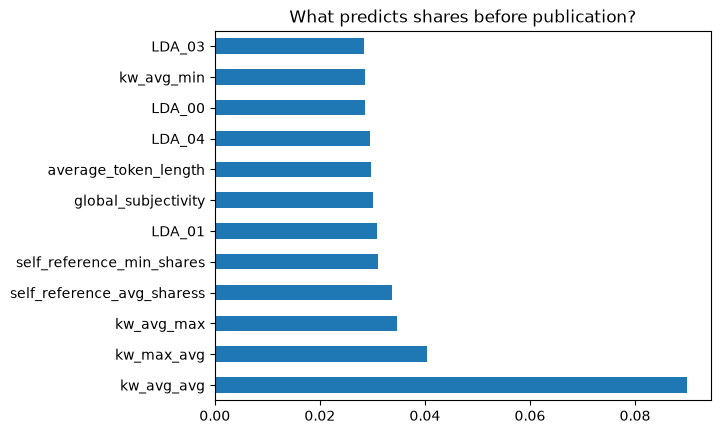

In [3]:
imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)
print(imp.head(12))
imp.head(12).plot(kind='barh', title='What predicts shares before publication?')